
DIGITAL SIGNAL PROCESSING LABORATORY

WEEK 1 — LAB 0: SETTING UP THE DSP LABORATORY

Name: Mary Emanuel Lameck

Registration Number: 240242458966

Module Code: COU 07506

Module: Digital Signal Processing

Department: Computer Studies

Class: BENG24COE- 02




In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

print("DSP Laboratory is ready!")


DSP Laboratory is ready!


TASK 1.1 – YOUR FIRST NOTEBOOK

Objective:

To generate and plot elementary discrete-time signals.

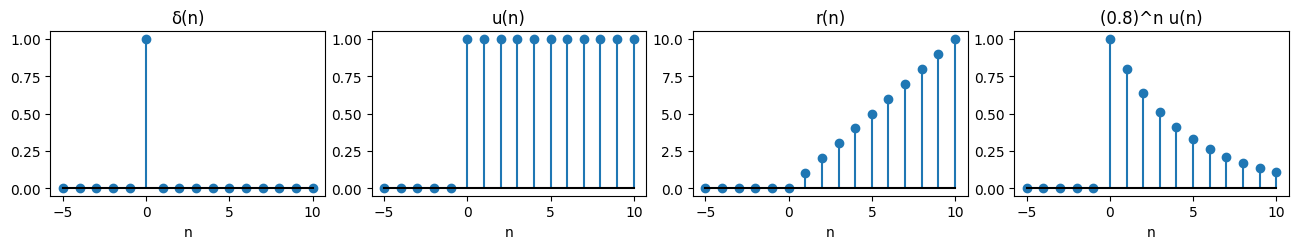

In [2]:
# Generate discrete-time index
n = np.arange(-5, 11)

# Unit impulse
delta = (n == 0).astype(float)

# Unit step
step = (n >= 0).astype(float)

# Unit ramp
ramp = n * step

# Real exponential
expo = 0.8**n * step

# Plot all four signals
fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))

for ax, x, title in zip(
    axes,
    [delta, step, ramp, expo],
    ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]
):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")

plt.tight_layout()
plt.show()

TASK 1.2 — CHANGE THE PARAMETERS

Part A: Exponential Signals


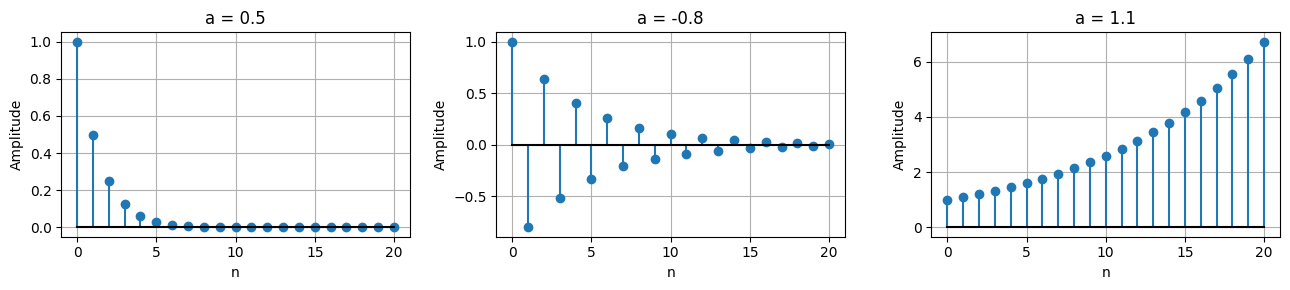

In [5]:
# Generate discrete-time indices
n = np.arange(0, 21)

# Define exponential parameters
a_values = [0.5, -0.8, 1.1]

# Create subplots
fig, axes = plt.subplots(1, 3, figsize=(13, 3))

# Generate and plot each exponential
for ax, a in zip(axes, a_values):

    x = a**n

    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"a = {a}")
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")
    ax.grid()

plt.tight_layout()
plt.show()

Part B:  Periodicity of cosine signals

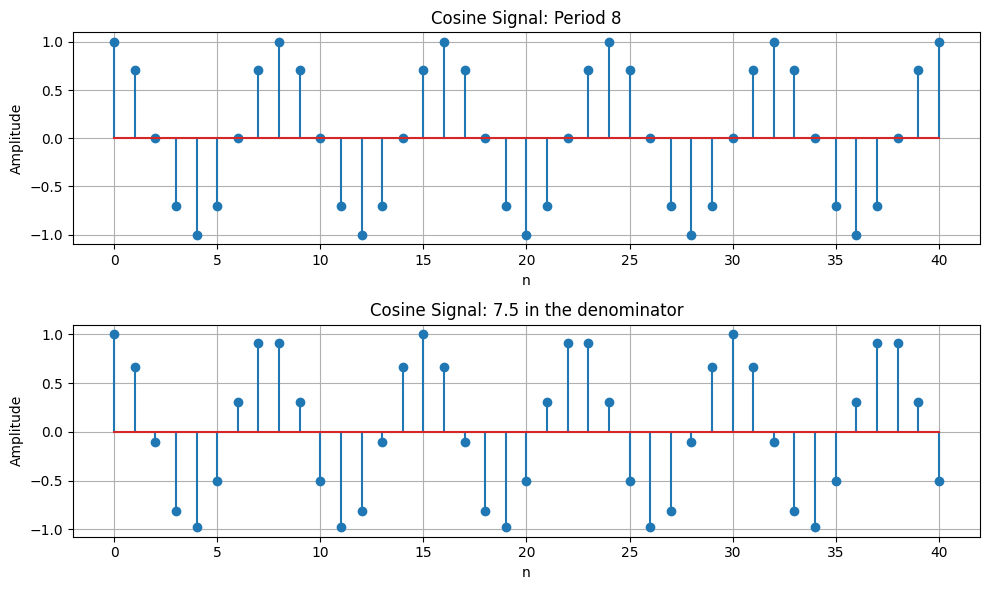

In [6]:
# Generate discrete-time indices
n = np.arange(0, 41)

# Generate cosine signals
x1 = np.cos(2*np.pi*n/8)
x2 = np.cos(2*np.pi*n/7.5)

# Create two subplots
fig, axes = plt.subplots(2, 1, figsize=(10, 6))

# Plot first cosine
axes[0].stem(n, x1)
axes[0].set_title("Cosine Signal: Period 8")
axes[0].set_xlabel("n")
axes[0].set_ylabel("Amplitude")
axes[0].grid()

# Plot second cosine
axes[1].stem(n, x2)
axes[1].set_title("Cosine Signal: 7.5 in the denominator")
axes[1].set_xlabel("n")
axes[1].set_ylabel("Amplitude")
axes[1].grid()

plt.tight_layout()
plt.show()

TASK 1.3 – WORKING WITH AUDIO

Objective:

To record, read, visualize and play an audio signal
using Python.

In [7]:
!apt-get -qq install ffmpeg

In [8]:
!ffmpeg -i My_voice.mp4 -ar 44100 -ac 1 my_voice.wav

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [10]:
!ffmpeg -y -i "My_voice.mp4" -ar 44100 -ac 1 "my_voice.wav"

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [11]:
import os

print(os.path.exists("my_voice.wav"))

True


In [12]:
fs, x = wavfile.read("my_voice.wav")

print("Sampling frequency:", fs, "Hz")
print("Audio duration:", len(x)/fs, "seconds")
print("Number of samples:", len(x))

Sampling frequency: 44100 Hz
Audio duration: 4.5226530612244895 seconds
Number of samples: 199449


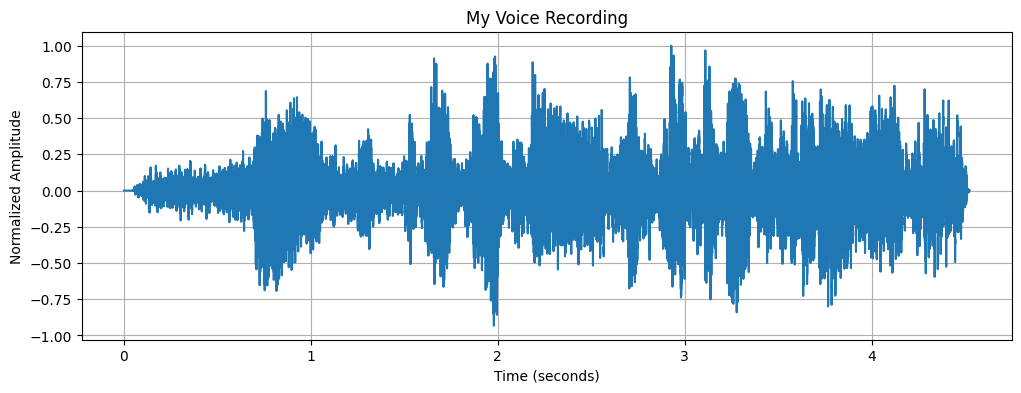

In [13]:
# Convert audio to floating-point values
x = x.astype(float)

# Normalize audio
x = x / np.max(np.abs(x))

# Generate time axis
t = np.arange(len(x)) / fs

# Plot voice waveform
plt.figure(figsize=(12, 4))
plt.plot(t, x)

plt.title("My Voice Recording")
plt.xlabel("Time (seconds)")
plt.ylabel("Normalized Amplitude")
plt.grid()
plt.show()

In [14]:
from IPython.display import Audio

Audio(x, rate=fs)